# The enhanced search vs plain alpha-beta (the v4 engine)

The v4 search — plain alpha-beta plus quiescence and forward pruning — measured against the plain search it extends: position tables, the depth and pruning ladders, a head-to-head, a common trajectory and the transposition-table measurement.

In [1]:
import os
import sys
import time
from collections import Counter
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "tuning" / "default.json").is_file())
os.environ["WEIGHTS_FILE"] = str(ROOT / "tuning" / "winner.json")
sys.path.insert(0, str(ROOT / "tuning"))

import harness
from connect6.board import copy_board, is_board_empty, make_move, opponent, unmake_move
from connect6.candidates import generate_candidate_moves
from connect6.defines import GRID_NUM, MAXINT, MININT, MAX_CANDIDATE_MOVES, Color, Move, Position, SearchStats, SearchResult
from connect6.evaluation import evaluate
from connect6.protocol import move2msg
from connect6.search import search_alpha_beta, search_alpha_beta_with_quiescence

print(f"weights pinned to {os.environ['WEIGHTS_FILE']} (the shipped champion)")


weights pinned to /Users/e.butovka/Documents/MyProjects/Connect6Engine/tuning/winner.json (the shipped champion)


## Position tables

The five positions come from tuning/harness.py (documented_positions).

In [2]:
DEPTH_PLAN = {
    "opening scatter, white to move": (2, 3, 4),
    "midgame, white to move": (2, 3, 4),
    "fork attack, black to move": (2, 3, 4),
    "fork completed, white to move": (1, 2, 3),
    "five-run attack, white to move": (2, 3, 4),
}

table_rows = {}
for label, board, color, pre_move in harness.documented_positions():
    depths = DEPTH_PLAN.get(label)
    if depths is None:
        continue
    print(f"== {label} ==")
    print(f"{'method':9s} {'depth':5s} {'nodes':>7s} {'ms':>8s} {'score':>7s}  move")
    for depth in depths:
        for name, search in (("plain", search_alpha_beta), ("enhanced", search_alpha_beta_with_quiescence)):
            stats = SearchStats()
            start = time.perf_counter()
            result = search(board, color, depth, pre_move, stats)
            elapsed = (time.perf_counter() - start) * 1000
            marker = " <- win verdict" if result.score in (MAXINT, -MAXINT) else ""
            print(f"{name:9s} {depth:5d} {stats.node_count:7d} {elapsed:8.1f} {result.score:7d}  {move2msg(result.move)}{marker}")
            table_rows[(label, name, depth)] = (stats.node_count, result.score, move2msg(result.move))
    print()

== opening scatter, white to move ==
method    depth   nodes       ms   score  move
plain         2     164     24.0     -40  CIIP
enhanced      2     164     44.6     -40  CIIP


plain         3    1593    142.3    -436  CIIP


enhanced      3    1668    313.7    -386  CKJP


plain         4   15964   2322.7     -40  CKJP


enhanced      4    7581   2395.7     -38  CKJP

== midgame, white to move ==
method    depth   nodes       ms   score  move
plain         2     191     24.7    -134  FJII
enhanced      2     402    116.2    -134  FJII


plain         3    1425    191.8   -2342  FJII


... (2 outputs left out)

enhanced      4    3782   1537.0    -617  JGII

== fork attack, black to move ==
method    depth   nodes       ms   score  move
plain         2     173     24.9     742  FJJN
enhanced      2      32     18.2   20000  JNBJ <- win verdict
plain         3      78     19.3   20000  JNBJ <- win verdict
enhanced      3      78     26.4   20000  JNBJ <- win verdict
plain         4     347     45.0   20000  JNBJ <- win verdict
enhanced      4     179     68.2   20000  JNBJ <- win verdict

== fork completed, white to move ==
method    depth   nodes       ms   score  move
plain         1      31      2.4     742  JMFE


enhanced      1      31     18.6   20000  GJHJ <- win verdict
plain         2      77     19.4   20000  GJHJ <- win verdict
enhanced      2      77     28.2   20000  GJHJ <- win verdict
plain         3     347     46.2   20000  GJHJ <- win verdict
enhanced      3     207    111.7   20000  GJHJ <- win verdict

== five-run attack, white to move ==
method    depth   nodes       ms   score  move
plain         2      90     14.7   10460  HJBJ
enhanced      2      87     26.0   20000  HJBJ <- win verdict


plain         3     249     36.4    1536  HJBJ
enhanced      3     103     34.9   20000  HJBJ <- win verdict


plain         4    1616    194.9   11596  HJBJ
enhanced      4     110     30.5   20000  HJBJ <- win verdict



## Validation

The cell below re-checks every measured row: nodes, score, move.

In [3]:
EXPECTED_ROWS = {
    ("opening scatter, white to move", "plain", 2): (164, -40, "CIIP"),
    ("opening scatter, white to move", "enhanced", 2): (164, -40, "CIIP"),
    ("opening scatter, white to move", "plain", 3): (1593, -436, "CIIP"),
    ("opening scatter, white to move", "enhanced", 3): (1668, -386, "CKJP"),
    ("opening scatter, white to move", "plain", 4): (15964, -40, "CKJP"),
    ("opening scatter, white to move", "enhanced", 4): (7581, -38, "CKJP"),
    ("midgame, white to move", "plain", 2): (191, -134, "FJII"),
    ("midgame, white to move", "enhanced", 2): (402, -134, "FJII"),
    ("midgame, white to move", "plain", 3): (1425, -2342, "FJII"),
    ("midgame, white to move", "enhanced", 3): (1458, -703, "BJII"),
    ("midgame, white to move", "plain", 4): (11799, -305, "FJKI"),
    ("midgame, white to move", "enhanced", 4): (3782, -617, "JGII"),
    ("fork attack, black to move", "plain", 2): (173, 742, "FJJN"),
    ("fork attack, black to move", "enhanced", 2): (32, 20000, "JNBJ"),
    ("fork attack, black to move", "plain", 3): (78, 20000, "JNBJ"),
    ("fork attack, black to move", "enhanced", 3): (78, 20000, "JNBJ"),
    ("fork attack, black to move", "plain", 4): (347, 20000, "JNBJ"),
    ("fork attack, black to move", "enhanced", 4): (179, 20000, "JNBJ"),
    ("fork completed, white to move", "plain", 1): (31, 742, "JMFE"),
    ("fork completed, white to move", "enhanced", 1): (31, 20000, "GJHJ"),
    ("fork completed, white to move", "plain", 2): (77, 20000, "GJHJ"),
    ("fork completed, white to move", "enhanced", 2): (77, 20000, "GJHJ"),
    ("fork completed, white to move", "plain", 3): (347, 20000, "GJHJ"),
    ("fork completed, white to move", "enhanced", 3): (207, 20000, "GJHJ"),
    ("five-run attack, white to move", "plain", 2): (90, 10460, "HJBJ"),
    ("five-run attack, white to move", "enhanced", 2): (87, 20000, "HJBJ"),
    ("five-run attack, white to move", "plain", 3): (249, 1536, "HJBJ"),
    ("five-run attack, white to move", "enhanced", 3): (103, 20000, "HJBJ"),
    ("five-run attack, white to move", "plain", 4): (1616, 11596, "HJBJ"),
    ("five-run attack, white to move", "enhanced", 4): (110, 20000, "HJBJ"),
}

for key, expected in EXPECTED_ROWS.items():
    measured = table_rows[key]
    assert measured == expected, f"{key}: measured {measured}, expected {expected}"
print(f"all {len(EXPECTED_ROWS)} position rows reproduce exactly (nodes, score, move)")

all 30 position rows reproduce exactly (nodes, score, move)


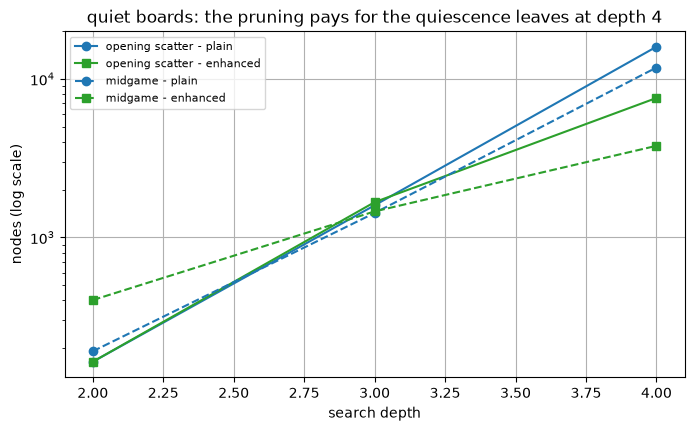

In [4]:
import matplotlib.pyplot as plt

quiet = ("opening scatter, white to move", "midgame, white to move")
fig, ax = plt.subplots(figsize=(8, 4.5))
styles = {quiet[0]: "-", quiet[1]: "--"}
for label in quiet:
    for name, color in (("plain", "tab:blue"), ("enhanced", "tab:green")):
        depths = DEPTH_PLAN[label]
        nodes = [table_rows[(label, name, d)][0] for d in depths]
        ax.plot(depths, nodes, marker="o" if name == "plain" else "s", color=color,
                linestyle=styles[label], label=f"{label.split(',')[0]} - {name}")
ax.set_yscale("log")
ax.set_xlabel("search depth")
ax.set_ylabel("nodes (log scale)")
ax.set_title("quiet boards: the pruning pays for the quiescence leaves at depth 4")
ax.grid(True)
ax.legend(fontsize=8)
plt.show()

## The depth ladder

Plain alpha-beta against the enhanced search, depths 1-5, on one quiet and one tactical position: growth and node cut.

In [5]:
LADDER_POSITIONS = ("opening scatter, white to move", "five-run attack, white to move")
LADDER_DEPTHS = (1, 2, 3, 4, 5)

ladder = {}
for label, board, color, pre_move in harness.documented_positions():
    if label not in LADDER_POSITIONS:
        continue
    for depth in LADDER_DEPTHS:
        for name, search in (("plain", search_alpha_beta), ("enhanced", search_alpha_beta_with_quiescence)):
            stats = SearchStats()
            start = time.perf_counter()
            result = search(board, color, depth, pre_move, stats)
            ladder[(label, name, depth)] = (
                stats.node_count, (time.perf_counter() - start) * 1000, result.score, move2msg(result.move),
            )

for label in LADDER_POSITIONS:
    print(f"== {label} ==")
    print(f"{'depth':5s} {'plain ms':>10s} {'nodes':>8s} {'growth':>7s}   {'enh ms':>9s} {'nodes':>8s} {'growth':>7s} {'node cut':>8s}  verdict")
    for depth in LADDER_DEPTHS:
        p_nodes, p_ms = ladder[(label, "plain", depth)][:2]
        e_nodes, e_ms, e_score, _ = ladder[(label, "enhanced", depth)]
        p_growth = "-" if depth == 1 else f"x{p_nodes / ladder[(label, 'plain', depth - 1)][0]:.1f}"
        e_growth = "-" if depth == 1 else f"x{e_nodes / ladder[(label, 'enhanced', depth - 1)][0]:.1f}"
        verdict = "proven loss" if e_score in (MAXINT, MININT) else "-"
        print(f"{depth:<5d} {p_ms:>10.1f} {p_nodes:>8,d} {p_growth:>7s}   {e_ms:>9.1f} {e_nodes:>8,d} {e_growth:>7s} "
              f"x{p_nodes / e_nodes:>7.2f}  {verdict}")
    print()

== opening scatter, white to move ==
depth   plain ms    nodes  growth      enh ms    nodes  growth node cut  verdict
1            1.8       31       -         2.1       31       - x   1.00  -
2           21.4      164    x5.3        44.3      164    x5.3 x   1.00  -
3          140.7    1,593    x9.7       330.3    1,668   x10.2 x   0.96  -
4         2364.9   15,964   x10.0      2476.3    7,581    x4.5 x   2.11  -
5        17890.9  149,270    x9.4     23317.7   67,443    x8.9 x   2.21  -

== five-run attack, white to move ==
depth   plain ms    nodes  growth      enh ms    nodes  growth node cut  verdict
1            1.9       31       -        13.0       31       - x   1.00  -
2           15.4       90    x2.9        27.2       87    x2.8 x   1.03  proven loss
3           36.9      249    x2.8        34.3      103    x1.2 x   2.42  proven loss
4          193.7    1,616    x6.5        30.4      110    x1.1 x  14.69  proven loss
5          786.7    3,820    x2.4        31.9      112    

In [6]:
EXPECTED_LADDER = {
    ("opening scatter, white to move", "plain", 1): (31, -123, "CKIP"),
    ("opening scatter, white to move", "plain", 2): (164, -40, "CIIP"),
    ("opening scatter, white to move", "plain", 3): (1593, -436, "CIIP"),
    ("opening scatter, white to move", "plain", 4): (15964, -40, "CKJP"),
    ("opening scatter, white to move", "plain", 5): (149270, -2201, "CKKP"),
    ("opening scatter, white to move", "enhanced", 1): (31, -123, "CKIP"),
    ("opening scatter, white to move", "enhanced", 2): (164, -40, "CIIP"),
    ("opening scatter, white to move", "enhanced", 3): (1668, -386, "CKJP"),
    ("opening scatter, white to move", "enhanced", 4): (7581, -38, "CKJP"),
    ("opening scatter, white to move", "enhanced", 5): (67443, -336, "IKKP"),
    ("five-run attack, white to move", "plain", 1): (31, 629, "HJBJ"),
    ("five-run attack, white to move", "plain", 2): (90, 10460, "HJBJ"),
    ("five-run attack, white to move", "plain", 3): (249, 1536, "HJBJ"),
    ("five-run attack, white to move", "plain", 4): (1616, 11596, "HJBJ"),
    ("five-run attack, white to move", "plain", 5): (3820, 3686, "HJBJ"),
    ("five-run attack, white to move", "enhanced", 1): (31, 629, "HJBJ"),
    ("five-run attack, white to move", "enhanced", 2): (87, 20000, "HJBJ"),
    ("five-run attack, white to move", "enhanced", 3): (103, 20000, "HJBJ"),
    ("five-run attack, white to move", "enhanced", 4): (110, 20000, "HJBJ"),
    ("five-run attack, white to move", "enhanced", 5): (112, 20000, "HJBJ"),
}
for key, (nodes, score, move) in EXPECTED_LADDER.items():
    measured = ladder[key]
    assert (measured[0], measured[2], measured[3]) == (nodes, score, move), key
for (label, name, depth), (nodes, score, move) in EXPECTED_ROWS.items():
    if label in LADDER_POSITIONS:
        measured = ladder[(label, name, depth)]
        assert (measured[0], measured[2], measured[3]) == (nodes, score, move), (label, name, depth)
print("the ladder pins every rung (depths 1-5, both searches) and reproduces "
      "the position tables at the shared depths exactly")

the ladder pins every rung (depths 1-5, both searches) and reproduces the position tables at the shared depths exactly


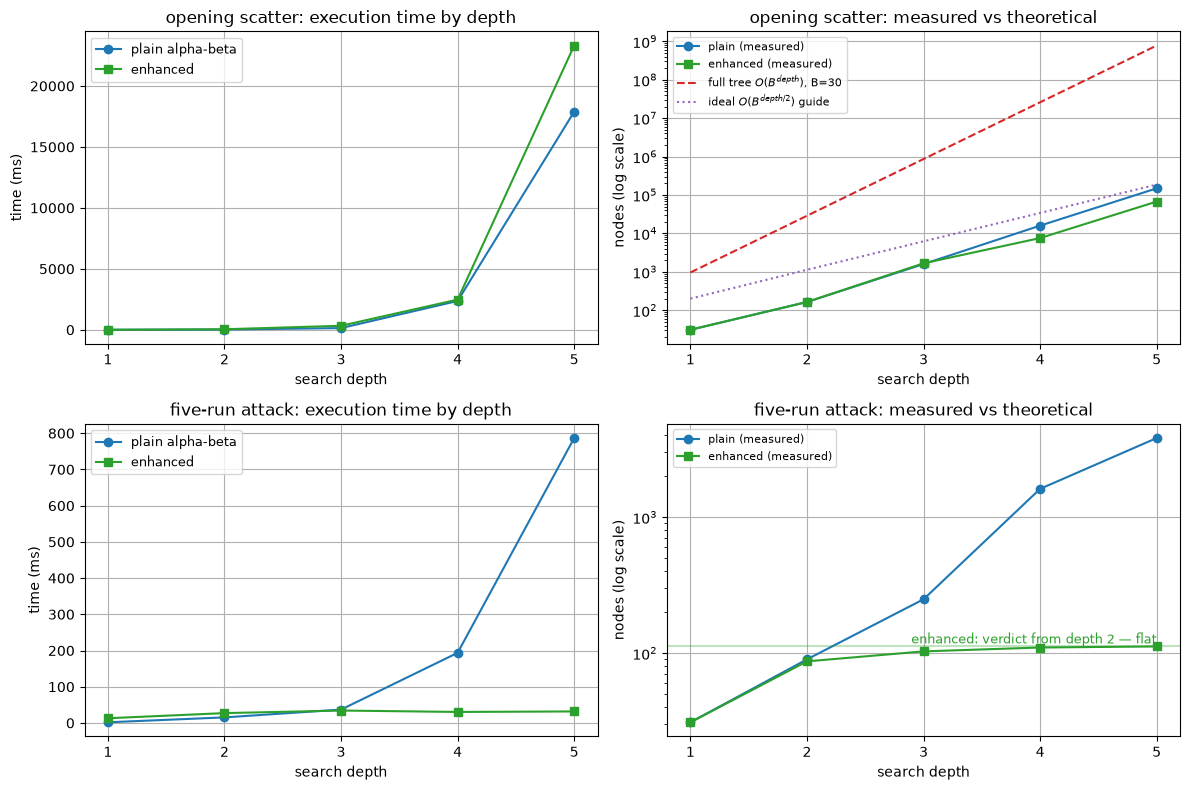

In [7]:
import matplotlib.pyplot as plt

BRANCHING = MAX_CANDIDATE_MOVES
anchor = ladder[(LADDER_POSITIONS[0], "plain", 1)][0]
full_tree = [anchor * sum(BRANCHING ** k for k in range(d + 1)) for d in LADDER_DEPTHS]
ideal_tree = [anchor * sum(BRANCHING ** (k / 2) for k in range(d + 1)) for d in LADDER_DEPTHS]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for row, label in enumerate(LADDER_POSITIONS):
    short = label.split(",")[0]
    plain_ms = [ladder[(label, "plain", d)][1] for d in LADDER_DEPTHS]
    enhanced_ms = [ladder[(label, "enhanced", d)][1] for d in LADDER_DEPTHS]
    plain_nodes = [ladder[(label, "plain", d)][0] for d in LADDER_DEPTHS]
    enhanced_nodes = [ladder[(label, "enhanced", d)][0] for d in LADDER_DEPTHS]

    ax = axes[row][0]
    ax.plot(LADDER_DEPTHS, plain_ms, marker="o", color="tab:blue", label="plain alpha-beta")
    ax.plot(LADDER_DEPTHS, enhanced_ms, marker="s", color="tab:green", label="enhanced")
    ax.set_xlabel("search depth")
    ax.set_ylabel("time (ms)")
    ax.set_title(f"{short}: execution time by depth")
    ax.set_xticks(LADDER_DEPTHS)
    ax.grid(True)
    ax.legend(fontsize=9)

    ax = axes[row][1]
    ax.semilogy(LADDER_DEPTHS, plain_nodes, marker="o", color="tab:blue", label="plain (measured)")
    ax.semilogy(LADDER_DEPTHS, enhanced_nodes, marker="s", color="tab:green", label="enhanced (measured)")
    if row == 0:
        ax.semilogy(LADDER_DEPTHS, full_tree, linestyle="--", color="tab:red", label=f"full tree $O(B^{{depth}})$, B={BRANCHING}")
        ax.semilogy(LADDER_DEPTHS, ideal_tree, linestyle=":", color="tab:purple", label=f"ideal $O(B^{{depth/2}})$ guide")
    else:
        first_verdict = LADDER_DEPTHS[next(i for i, d in enumerate(LADDER_DEPTHS)
                                           if ladder[(label, "enhanced", d)][2] in (MAXINT, MININT))]
        ax.axhline(enhanced_nodes[-1], color="tab:green", alpha=0.3)
        ax.annotate(f"enhanced: verdict from depth {first_verdict} — flat",
                    (LADDER_DEPTHS[-1], enhanced_nodes[-1]), ha="right", va="bottom", fontsize=9, color="tab:green")
    ax.set_xlabel("search depth")
    ax.set_ylabel("nodes (log scale)")
    ax.set_title(f"{short}: measured vs theoretical")
    ax.set_xticks(LADDER_DEPTHS)
    ax.grid(True)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## The pruning ladder

The enhanced search with FORWARD_WIDTHS replaced by a constant width 30, same two positions, depths 1-5.

In [8]:
import connect6.search as search_module

assert search_module.FORWARD_WIDTHS == (30, 30, 16, 10)
search_module.FORWARD_WIDTHS = (30,) * 7
try:
    wide = {}
    for label, board, color, pre_move in harness.documented_positions():
        if label not in LADDER_POSITIONS:
            continue
        for depth in LADDER_DEPTHS:
            stats = SearchStats()
            start = time.perf_counter()
            result = search_alpha_beta_with_quiescence(board, color, depth, pre_move, stats)
            wide[(label, depth)] = (
                stats.node_count, (time.perf_counter() - start) * 1000, result.score, move2msg(result.move),
            )
finally:
    search_module.FORWARD_WIDTHS = (30, 30, 16, 10)
assert search_module.FORWARD_WIDTHS == (30, 30, 16, 10)

for label in LADDER_POSITIONS:
    print(f"== {label} ==")
    print(f"{'depth':5s} {'width-30 ms':>12s} {'nodes':>8s} {'growth':>7s}   {'tiered nodes':>12s} {'growth':>7s} {'pruning cut':>11s}")
    for depth in LADDER_DEPTHS:
        w_nodes, w_ms = wide[(label, depth)][:2]
        t_nodes = ladder[(label, "enhanced", depth)][0]
        w_growth = "-" if depth == 1 else f"x{w_nodes / wide[(label, depth - 1)][0]:.1f}"
        t_growth = "-" if depth == 1 else f"x{t_nodes / ladder[(label, 'enhanced', depth - 1)][0]:.1f}"
        print(f"{depth:<5d} {w_ms:>12.1f} {w_nodes:>8,d} {w_growth:>7s}   {t_nodes:>12,d} {t_growth:>7s} "
              f"x{w_nodes / t_nodes:>10.2f}")
    print()

== opening scatter, white to move ==
depth  width-30 ms    nodes  growth   tiered nodes  growth pruning cut
1              2.4       31       -             31       - x      1.00
2             44.3      164    x5.3            164    x5.3 x      1.00
3            408.1    2,764   x16.9          1,668   x10.2 x      1.66
4           5273.4   18,878    x6.8          7,581    x4.5 x      2.49
5         137929.5  376,459   x19.9         67,443    x8.9 x      5.58

== five-run attack, white to move ==
depth  width-30 ms    nodes  growth   tiered nodes  growth pruning cut
1             13.1       31       -             31       - x      1.00
2             27.6       87    x2.8             87    x2.8 x      1.00
3             48.3      131    x1.5            103    x1.2 x      1.27
4             37.5      138    x1.1            110    x1.1 x      1.25
5             48.9      160    x1.2            112    x1.0 x      1.43



In [9]:
EXPECTED_WIDTHS = {
    ("opening scatter, white to move", 1): (31, -123, "CKIP"),
    ("opening scatter, white to move", 2): (164, -40, "CIIP"),
    ("opening scatter, white to move", 3): (2764, -430, "CIIP"),
    ("opening scatter, white to move", 4): (18878, -40, "CKJP"),
    ("opening scatter, white to move", 5): (376459, -607, "CIKP"),
    ("five-run attack, white to move", 1): (31, 629, "HJBJ"),
    ("five-run attack, white to move", 2): (87, 20000, "HJBJ"),
    ("five-run attack, white to move", 3): (131, 20000, "HJBJ"),
    ("five-run attack, white to move", 4): (138, 20000, "HJBJ"),
    ("five-run attack, white to move", 5): (160, 20000, "HJBJ"),
}
for key, (nodes, score, move) in EXPECTED_WIDTHS.items():
    measured = wide[key]
    assert (measured[0], measured[2], measured[3]) == (nodes, score, move), key
for label in LADDER_POSITIONS:
    for depth in (1, 2):
        assert wide[(label, depth)][0] == ladder[(label, "enhanced", depth)][0], (label, depth)
print("the constant-width trees are pinned; depths 1-2 are identical to the tiered ones "
      "(the tiers have not engaged yet)")

the constant-width trees are pinned; depths 1-2 are identical to the tiered ones (the tiers have not engaged yet)


## Head-to-head at the deployment depth

Both searches through the real referee: center opening, six seeded openings, depth 3, 60-ply cap.

In [10]:
SEEDS = ["IIKK", "JIKJ", "JKJI", "IKKJ", "LLHH", "HHGG"]
GAMES = 2 * len(SEEDS)

plans = []
for game in range(GAMES):
    seed = SEEDS[game % len(SEEDS)]
    enhanced_is_black = (game // len(SEEDS)) % 2 == 0
    black = harness.PlayerSpec(search_alpha_beta_with_quiescence if enhanced_is_black else search_alpha_beta)
    white = harness.PlayerSpec(search_alpha_beta if enhanced_is_black else search_alpha_beta_with_quiescence)
    plans.append((seed, enhanced_is_black, harness.GameSpec(black, white, 3, 60, seed)))

start = time.perf_counter()
records = harness.run_games([plan[2] for plan in plans])
print(f"== head-to-head at depth 3 (enhanced vs plain, {GAMES} games over {len(SEEDS)} openings, "
      f"{time.perf_counter() - start:.0f} s across twelve workers) ==")
games = []
for (seed, enhanced_is_black, _), record in zip(plans, records):
    if record.winner is None:
        outcome = "draw"
    else:
        enhanced_won = record.winner == (Color.BLACK if enhanced_is_black else Color.WHITE)
        outcome = "enhanced" if enhanced_won else "plain"
    stones = sum(1 for x in range(1, GRID_NUM - 1) for y in range(1, GRID_NUM - 1) if record.board[x][y] != 0)
    games.append((seed, enhanced_is_black, outcome, stones))
    enhanced_tally = record.black if enhanced_is_black else record.white
    plain_tally = record.white if enhanced_is_black else record.black
    print(f"game {len(games):2d}: opening {seed}, enhanced as {'black' if enhanced_is_black else 'white'}: "
          f"{outcome:9s} {stones} stones | enhanced {enhanced_tally.nodes:,} nodes, "
          f"{enhanced_tally.ms / max(enhanced_tally.moves, 1):.0f} ms/move | "
          f"plain {plain_tally.nodes:,} nodes, {plain_tally.ms / max(plain_tally.moves, 1):.0f} ms/move")


== head-to-head at depth 3 (enhanced vs plain, 12 games over 6 openings, 105 s across twelve workers) ==
game  1: opening IIKK, enhanced as black: enhanced  81 stones | enhanced 52,552 nodes, 1470 ms/move | plain 31,770 nodes, 355 ms/move
game  2: opening JIKJ, enhanced as black: enhanced  53 stones | enhanced 76,114 nodes, 3002 ms/move | plain 25,835 nodes, 359 ms/move
game  3: opening JKJI, enhanced as black: enhanced  97 stones | enhanced 136,378 nodes, 2843 ms/move | plain 40,495 nodes, 341 ms/move
game  4: opening IKKJ, enhanced as black: enhanced  41 stones | enhanced 37,773 nodes, 2066 ms/move | plain 17,618 nodes, 353 ms/move
game  5: opening LLHH, enhanced as black: enhanced  29 stones | enhanced 32,853 nodes, 2490 ms/move | plain 7,512 nodes, 198 ms/move
game  6: opening HHGG, enhanced as black: enhanced  29 stones | enhanced 11,416 nodes, 948 ms/move | plain 6,905 nodes, 254 ms/move
game  7: opening IIKK, enhanced as white: enhanced  39 stones | enhanced 18,297 nodes, 1135 m

In [11]:
outcomes = [outcome for _, _, outcome, _ in games]
assert outcomes.count("enhanced") == 11, f"wins: {outcomes.count('enhanced')}"
assert outcomes.count("plain") == 1, f"losses: {outcomes.count('plain')}"
assert outcomes.count("draw") == 0
stones = [s for *_, s in games]
assert 25 <= min(stones) and max(stones) <= 97
print("head-to-head record: enhanced wins 11-1 of 12, 25-97 stones")

head-to-head record: enhanced wins 11-1 of 12, 25-97 stones


## A common trajectory

One deterministic self-play game, then every decision point re-analyzed by both searches at the deployment depth.

In [12]:
EXPECTED_HISTORY = 'JJ IIKK JKLJ KJKI KLJI JLIJ JHLH JGIH KHLI LKIG IKIF LGHG KGKF KEJF HHMJ MHNK GGLF MEML NMLM MNLE JENE MKLD OKMC MMNJ MOHK LLOI KMPH NLNI NHNN GKHI GJOM OJPL OLPK ONLN PIIL FIKN GIHL GHHJ GMQJ FNRI FGHM FLKO EMJP FMGN PJLP KQPG FOIM JMHO INEL'.split()

enhanced_player = harness.search_player(search_alpha_beta_with_quiescence)
trajectory = harness.play_game(enhanced_player, enhanced_player, 3, white_first_reply="IIKK", max_plies=48)
history = ["JJ"] + trajectory.moves
assert history == EXPECTED_HISTORY
assert trajectory.winner is None and trajectory.plies == 48
assert (trajectory.black.nodes, trajectory.white.nodes) == (144203, 173211)
import json

fixture = json.loads((ROOT / "benchmarks" / "trajectory.json").read_text())
assert history == fixture["history"]
print(f"trajectory: 48-ply v4 self-play, no win inside the cap, "
      f"black {trajectory.black.nodes:,} / white {trajectory.white.nodes:,} nodes to generate it; "
      f"fixture identity: benchmarks/trajectory.json (move-for-move)")

rows = harness.analyze_history(history, [("v3", search_alpha_beta), ("v4", search_alpha_beta_with_quiescence)], 3)
per_prefix = {}
for row in rows:
    per_prefix.setdefault(row.prefix, {})[row.name] = row
positions = sorted(per_prefix)
n = len(positions)

totals = {name: sum(per_prefix[p][name].nodes for p in positions) for name in ("v3", "v4")}
changes = sum(1 for p in positions if per_prefix[p]["v3"].move != per_prefix[p]["v4"].move)
flips = sum(1 for p in positions if (abs(per_prefix[p]["v3"].score) >= 20000) != (abs(per_prefix[p]["v4"].score) >= 20000))
peak = max(positions, key=lambda p: per_prefix[p]["v4"].nodes)
print(f"{'engine':6s} {'total nodes':>12s} {'mean/position':>13s} {'peak':>8s}")
for name in ("v3", "v4"):
    top = max(per_prefix[p][name].nodes for p in positions)
    print(f"{name:6s} {totals[name]:12,d} {totals[name] // n:13,d} {top:8,d}")
print(f"move changes: {changes}/{n}   verdict-band flips: {flips}/{n}   v4 node peak: prefix {peak}")

trajectory: 48-ply v4 self-play, no win inside the cap, black 144,203 / white 173,211 nodes to generate it; fixture identity: benchmarks/trajectory.json (move-for-move)


engine  total nodes mean/position     peak
v3           84,596         1,762    3,847
v4          320,038         6,667   40,262
move changes: 27/48   verdict-band flips: 0/48   v4 node peak: prefix 40


In [13]:
EXPECTED_TRAJECTORY = {"v3_nodes": 84596, "v4_nodes": 320038, "changes": 27, "flips": 0, "v4_peak": 40262}
assert totals["v3"] == EXPECTED_TRAJECTORY["v3_nodes"]
assert totals["v4"] == EXPECTED_TRAJECTORY["v4_nodes"]
assert changes == EXPECTED_TRAJECTORY["changes"]
assert flips == EXPECTED_TRAJECTORY["flips"]
assert max(per_prefix[p]["v4"].nodes for p in positions) == EXPECTED_TRAJECTORY["v4_peak"]
print("trajectory rows reproduce exactly (nodes, move changes, verdict flips)")


trajectory rows reproduce exactly (nodes, move changes, verdict flips)


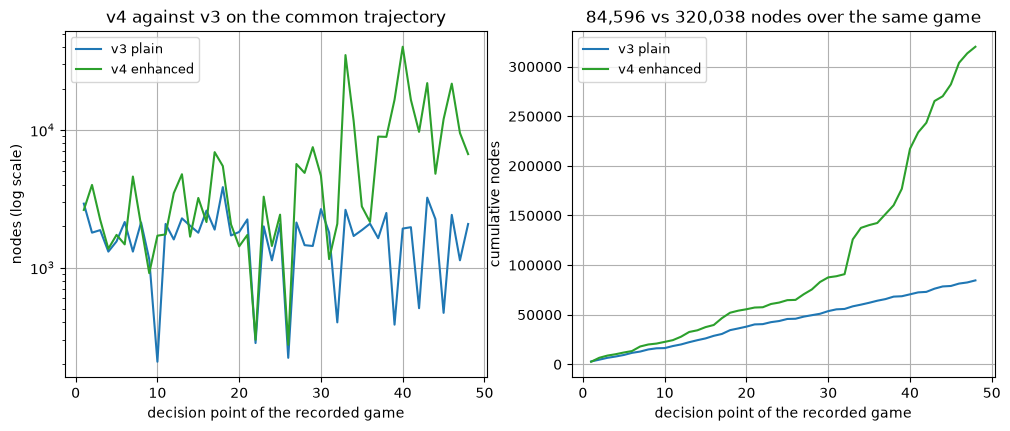

In [14]:
import matplotlib.pyplot as plt

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
ax.plot(positions, [per_prefix[p]["v3"].nodes for p in positions], color="tab:blue", label="v3 plain")
ax.plot(positions, [per_prefix[p]["v4"].nodes for p in positions], color="tab:green", label="v4 enhanced")
ax.set_yscale("log")
ax.set_xlabel("decision point of the recorded game")
ax.set_ylabel("nodes (log scale)")
ax.set_title("v4 against v3 on the common trajectory")
ax.grid(True)
ax.legend(fontsize=9)
ax2.plot(positions, [sum(per_prefix[q]["v3"].nodes for q in positions[:i + 1]) for i, p in enumerate(positions)], color="tab:blue", label="v3 plain")
ax2.plot(positions, [sum(per_prefix[q]["v4"].nodes for q in positions[:i + 1]) for i, p in enumerate(positions)], color="tab:green", label="v4 enhanced")
ax2.set_xlabel("decision point of the recorded game")
ax2.set_ylabel("cumulative nodes")
ax2.set_title("84,596 vs 320,038 nodes over the same game")
ax2.grid(True)
ax2.legend(fontsize=9)
plt.show()


## The declined enhancement: transposition tables

A replica of the plain search, instrumented with a revisit counter and a sound transposition table.

In [15]:
EXACT, LOWER, UPPER = 0, 1, 2


def position_key(board):
    return tuple(map(tuple, board))


def replica_ab(depth, board, color, pre_move, stats, alpha, beta, table=None, seen=None, hits=None):
    key = None
    if table is not None:
        key = (position_key(board), color)
        entry = table.get(key)
        if entry is not None and entry[0] >= depth:
            if hits is not None:
                hits[0] += 1
            flag, val, mv = entry[1]
            if flag == EXACT:
                return SearchResult(mv, val)
            if flag == LOWER and val >= beta:
                return SearchResult(mv, val)
            if flag == UPPER and val <= alpha:
                return SearchResult(mv, val)
    stats.node_count += 1
    if seen is not None:
        seen[(position_key(board), color)] += 1
    score = evaluate(board, pre_move)
    if score == MAXINT or score == MININT:
        if table is not None:
            table[key] = (depth, (EXACT, score, pre_move))
        return SearchResult(pre_move, score)
    if depth <= 0:
        if table is not None:
            table[key] = (depth, (EXACT, score, pre_move))
        return SearchResult(pre_move, score)
    candidates = generate_candidate_moves(board, MAX_CANDIDATE_MOVES, color)
    if len(candidates) == 0:
        if table is not None:
            table[key] = (depth, (EXACT, score, pre_move))
        return SearchResult(pre_move, score)
    maximizing = color == Color.BLACK
    best_score = MININT if maximizing else MAXINT
    best_move = candidates[0]
    a0, b0 = alpha, beta
    for candidate in candidates:
        make_move(board, candidate, color)
        child = replica_ab(depth - 1, board, opponent(color), candidate, stats, alpha, beta, table, seen, hits)
        unmake_move(board, candidate)
        if maximizing:
            if child.score > best_score:
                best_score, best_move = child.score, candidate
            if best_score >= beta:
                break
            if best_score > alpha:
                alpha = best_score
        else:
            if child.score < best_score:
                best_score, best_move = child.score, candidate
            if best_score <= alpha:
                break
            if best_score < beta:
                beta = best_score
    if table is not None:
        flag = UPPER if best_score <= a0 else (LOWER if best_score >= b0 else EXACT)
        table[key] = (depth, (flag, best_score, best_move))
    return SearchResult(best_move, best_score)


def replica(board, color, depth, pre_move, stats, table=None, seen=None, hits=None):
    working = copy_board(board)
    if is_board_empty(working):
        return SearchResult(Move((Position(10, 10), Position(10, 10))), 0)
    return replica_ab(depth, working, color, pre_move, stats, MININT, MAXINT, table, seen, hits)


tt_positions = [p for p in harness.documented_positions() if p[0].split(",")[0] in ("opening scatter", "midgame", "five-run attack")]
print("replica and sound table ready")


replica and sound table ready


In [16]:
EXPECTED_TT = {
    ("opening scatter, white to move", 3): (1593, 1545, 48, 48),
    ("opening scatter, white to move", 4): (15964, 15169, 658, 796),
    ("midgame, white to move", 3): (1425, 1217, 208, 208),
    ("midgame, white to move", 4): (11799, 10313, 1061, 1487),
    ("five-run attack, white to move", 3): (249, 249, 0, 0),
    ("five-run attack, white to move", 4): (1616, 1451, 165, 165),
}

print(f"{'position':28s} {'d':2s} {'nodes':>7s} {'TT nodes':>8s} {'saved':>6s} {'hits':>5s} {'revisits':>8s} {'TT ms':>6s} {'plain ms':>8s}")
for label, board, color, pre_move in tt_positions:
    for depth in (3, 4):
        plain_stats = SearchStats()
        start = time.perf_counter()
        plain = search_alpha_beta(board, color, depth, pre_move, plain_stats)
        plain_ms = (time.perf_counter() - start) * 1000
        replica_stats = SearchStats()
        result = replica(board, color, depth, pre_move, replica_stats)
        assert (replica_stats.node_count, result.score, result.move) == (plain_stats.node_count, plain.score, plain.move)
        seen = Counter()
        bound_stats = SearchStats()
        replica(board, color, depth, pre_move, bound_stats, seen=seen)
        revisits = bound_stats.node_count - len(seen)
        table = {}
        hits = [0]
        tt_stats = SearchStats()
        start = time.perf_counter()
        tt = replica(board, color, depth, pre_move, tt_stats, table=table, hits=hits)
        tt_ms = (time.perf_counter() - start) * 1000
        assert tt.score == plain.score and tt.move == plain.move
        assert EXPECTED_TT[(label, depth)] == (replica_stats.node_count, tt_stats.node_count, hits[0], revisits)
        saved = 100 * (replica_stats.node_count - tt_stats.node_count) / replica_stats.node_count
        print(f"{label:28s} {depth:2d} {replica_stats.node_count:7,d} {tt_stats.node_count:8,d} {saved:5.1f}% {hits[0]:5d} {revisits:8,d} {tt_ms:6.0f} {plain_ms:8.0f}")

def us_per_call(fn, n=20000):
    start = time.perf_counter()
    for _ in range(n):
        fn()
    return (time.perf_counter() - start) / n * 1e6

board, color, pre_move = tt_positions[1][1], tt_positions[1][2], tt_positions[1][3]
key = (position_key(board), Color.BLACK)
print(f"\nupkeep floor: position_key {us_per_call(lambda: position_key(board)):.1f} us, "
      f"dict probe {us_per_call(lambda: table.get(key)):.2f} us — against "
      f"evaluate {us_per_call(lambda: evaluate(board, pre_move)):.1f} us per node")
print("the recovered 3.0-14.6% of nodes buy a wall-clock wash: -7% to +2% across the six rows")


position                     d    nodes TT nodes  saved  hits revisits  TT ms plain ms


opening scatter, white to move  3   1,593    1,545   3.0%    48       48    147      143


opening scatter, white to move  4  15,964   15,169   5.0%   658      796   2426     2350


midgame, white to move        3   1,425    1,217  14.6%   208      208    190      194


midgame, white to move        4  11,799   10,313  12.6%  1061    1,487   1852     1985
five-run attack, white to move  3     249      249   0.0%     0        0     38       37


five-run attack, white to move  4   1,616    1,451  10.2%   165      165    189      195



upkeep floor: position_key 1.2 us, dict probe 0.03 us — against evaluate 40.3 us per node
the recovered 3.0-14.6% of nodes buy a wall-clock wash: -7% to +2% across the six rows


## Reading the results

Quiescence changes verdicts, not just moves; the extension horizon is bounded; the pruning pays off from depth 4.